# Human Activity Recognition using TSFEL

On this example, we will perform Human Activity Recognition using our library **Time Series Feature Extraction Library**.

To perform this example every cell must be executed. To do so click run ([  ]) in the top left of every cell.

The first step consists of importing the library.

The import can take a few seconds, but the run button will change so that you know the import has started and ended.

A warning will appear to reset all runtimes before running, click to accept.

In [1]:
import warnings

warnings.filterwarnings("ignore")
!pip install tsfel >/dev/null 2>&1

In [2]:
import tsfel
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import preprocessing
from matplotlib import pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Dataset
The dataset used in this example is AICOS-HAR, an open-source Human Activity Recognition (HAR) dataset available on [Zenodo](https://doi.org/10.5281/zenodo.19452049).

AICOS-HAR contains smartphone sensor recordings collected during different physical activities. The dataset includes measurements from several sensors, such as the accelerometer, gyroscope, magnetometer and barometer.

In this example, we will work with a small subset of the dataset, using accelerometer data only. We will consider the following activity classes:
*   Walking
*   Standing
*   Sitting
*   Running
*   Lying Down
*   Upstairs
*   Downstairs
*   Ramp up
*   Ramp down

For each activity, we select up to 10 acquisitions for training and 10 for testing, following the original dataset split information.

Each acquisition contains three acceleration axes (x, y, and z). The signals are resampled to 100 Hz using linear interpolation, and the acceleration magnitude (mag) is calculated from the three axes.


In [ ]:
# Load the data partitions
from tsfel.datasets._single_problem_loaders import load_aicoshar

X_train_sig, y_train, X_test_sig, y_test = load_aicoshar()
activity_labels = np.unique(np.concatenate([y_train, y_test]))
print("Training acquisitions:", len(X_train_sig))
print("Test acquisitions", len(X_test_sig))

# Dataset sampling frequency
fs = 100

Training acquisitions: 90
Test acquisitions 90


In [9]:
def plot_acquisition(X, y, activity, acquisition_idx=0):

    indices = [i for i, label in enumerate(y) if label == activity]
    signal = X[indices[acquisition_idx]]
    time = np.arange(len(signal)) / fs

    fig, axes = plt.subplots(4, 1, figsize=(14, 8), sharex=True)
    signal_names = ["X-axis", "Y-axis", "Z-axis", "Magnitude"]
    axis_color = "tab:blue"
    magnitude_color = "tab:orange"

    for i, ax in enumerate(axes):
        color = magnitude_color if i == 3 else axis_color
        ax.plot(time, signal[:, i], color=color, label=signal_names[i])
        ax.grid(False)
        ax.axis("off")
        ax.margins(x=0.01, y=0.15)
        ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)

    axes[-1].set_xlabel("Time (seconds)")
    fig.suptitle(f"Activity: {activity} | Acquisition: {acquisition_idx}")
    plt.tight_layout()
    plt.show()


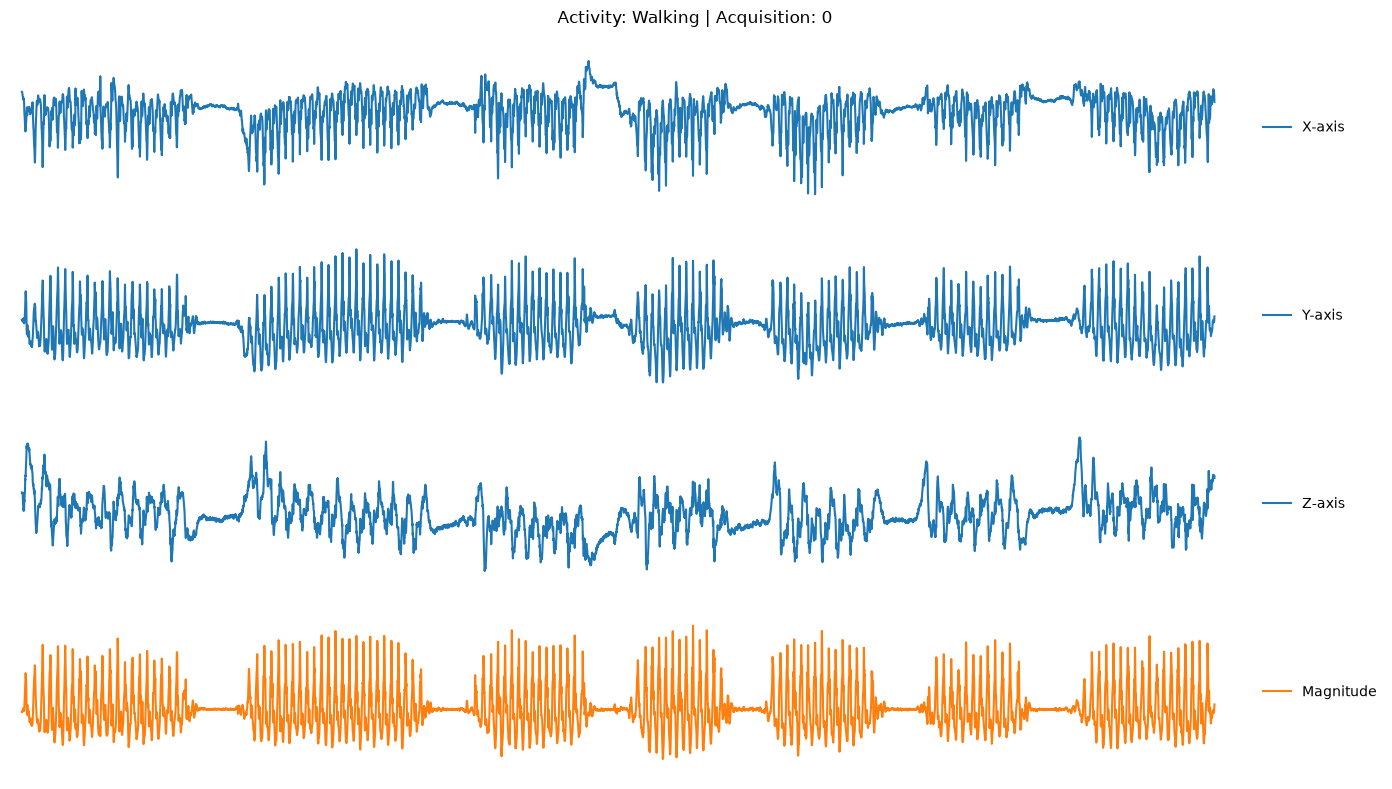

In [10]:
# Signal Preview
plot_acquisition(X_train_sig, y_train, "Walking")

# Feature Extraction

Through **Feature Extraction** methodologies, the data is translated into a feature vector containing information about the signal properties of each window. These properties can be classified according to their domain as Time, Frequency and Statistical features and allow to characterise the signal compactly, enhancing its characteristics. This features will be used as input to the machine learning classifier, thus, the chosen set of features can strongly influence the classification output.

In [5]:
# Feature Extraction
cfg_file = tsfel.get_features_by_domain()  # All features
# cfg_file = tsfel.get_features_by_domain('statistical') # Only statistical features
# cfg_file = tsfel.get_features_by_domain('temporal')    # Only temporal features
# cfg_file = tsfel.get_features_by_domain('spectral')    # Only spectral features

# Get features
X_train = tsfel.time_series_features_extractor(cfg_file, X_train_sig, fs=fs)
X_test = tsfel.time_series_features_extractor(cfg_file, X_test_sig, fs=fs)

Extracting features: 100%|██████████| 90/90 [00:14<00:00,  6.33window/s]


# Feature Selection

After the sensor data is extracted, redundancies and noise should be removed. Thus, minimising the algorithm's error, time and computational complexity. 

In [6]:
# Highly correlated features are removed
corr_features, X_train = tsfel.correlated_features(X_train, drop_correlated=True)
X_test.drop(corr_features, axis=1, inplace=True)

# Remove low variance features
selector = VarianceThreshold()
X_train = selector.fit_transform(X_train)
X_test = selector.transform(X_test)

# Normalising Features
scaler = preprocessing.StandardScaler()
nX_train = scaler.fit_transform(X_train)
nX_test = scaler.transform(X_test)

# Classification

In this example the classification is performed with a [Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) classifier.

In [ ]:
classifier = RandomForestClassifier()

# Train the classifier
classifier.fit(nX_train, y_train)

# Predict test data
y_test_predict = classifier.predict(nX_test)

# Get the classification report
accuracy = accuracy_score(y_test, y_test_predict) * 100
print(classification_report(y_test, y_test_predict, target_names=activity_labels))
print("Accuracy: " + str(accuracy) + "%")

              precision    recall  f1-score   support

  Downstairs       0.67      0.20      0.31        10
   LyingDown       0.47      0.70      0.56        10
    RampDown       0.00      0.00      0.00        10
      RampUp       0.33      0.20      0.25        10
     Running       0.75      0.90      0.82        10
     Sitting       0.67      0.40      0.50        10
    Standing       0.60      0.60      0.60        10
    Upstairs       0.18      0.30      0.22        10
     Walking       0.41      0.70      0.52        10

    accuracy                           0.44        90
   macro avg       0.45      0.44      0.42        90
weighted avg       0.45      0.44      0.42        90

Accuracy: 44.44444444444444%


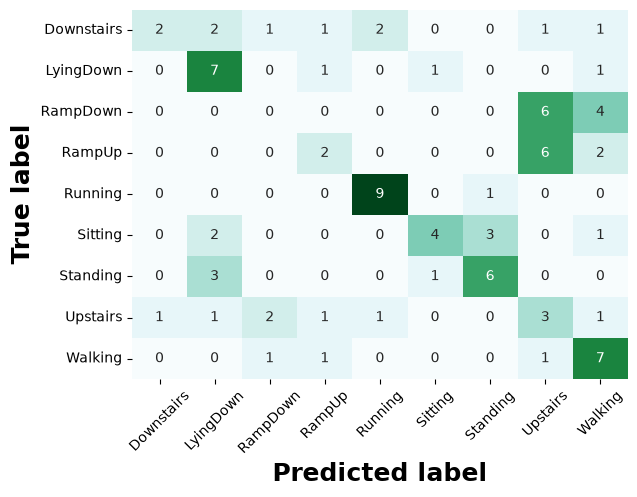

In [8]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_test_predict)
df_cm = pd.DataFrame(cm, index=[i for i in activity_labels], columns=[i for i in activity_labels])
plt.figure()
ax = sns.heatmap(df_cm, cbar=False, cmap="BuGn", annot=True, fmt="d")
plt.setp(ax.get_xticklabels(), rotation=45)

plt.ylabel("True label", fontweight="bold", fontsize=18)
plt.xlabel("Predicted label", fontweight="bold", fontsize=18)
bottom, top = ax.get_ylim()
plt.show()

# Conclusion

The confusion matrix shows that the model achieves moderate performance in the activity classification task, correctly classifying 43 out of 90 acquisitions, corresponding to an accuracy of 47.8%. Running is the best-recognized activity, with all 10 acquisitions correctly classified, followed by Walking, LyingDown, and Standing. However, the model struggles to distinguish between activities with similar movement patterns, particularly RampUp and RampDown, which are frequently misclassified as Upstairs. Overall, these results suggest that although the model can identify some activities reliably, its ability to distinguish between more similar movements remains limited.